# Baselines for Rating Prediction (1–5) on Cold-Start Recipes

**Main task.** Given a `(user_id, recipe_id)` pair where the recipe has no reviews in the training data, predict the rating (1–5) the user will give it. Models are trained with squared error and evaluated with **MSE**. Hyperparameters are chosen on the **validation** cold rows (2013); in Section 6 every baseline is refit on train + validation and evaluated once on the **test** split (2014–2018), with MSE and with the ranking metrics AUC, Hit@10 and NDCG@10.

A binary version of the same task (predict whether the rating is 5, evaluated with AUC) is in `02_baselines_binary.ipynb`; both use the same training rows, features, and evaluation protocol.

| | Baseline | Information used |
|---|---|---|
| B0 | global mean rating | none |
| B1 | ID-only bias model, $\alpha + \beta_u + \beta_i$ | user and recipe ids |
| B2 | ridge regression on user-history features | the user's past ratings |
| B3 | TF-IDF cosine (content-only): ridge regression on the similarity of the recipe text to the user's past recipes | recipe text + which past recipes the user loved |

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import features as F
import evaluate as E

import plots as P

P.setup()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

In [2]:
splits, recipes = F.load_data()
train, valid, test = splits["train"], splits["validation"], splits["test"]

# content representations use recipe content only (no ratings), so they can be built from all recipes
content = F.content_matrix(recipes, F.top_vocab(recipes.tags, F.N_TAGS), F.top_vocab(recipes.ingredients, F.N_INGREDIENTS))
X_text = F.tfidf_matrix(recipes)
print(f"TF-IDF over name + tags + ingredients + description + steps: {X_text.shape[0]:,} recipes x {X_text.shape[1]:,} terms")

TF-IDF over name + tags + ingredients + description + steps: 178,265 recipes x 20,425 terms


## 1. Pseudo-cold training set

The training split has no cold-start rows: every recipe in it has reviews. We therefore train on the reviews written **on the first day a recipe was reviewed**; at that moment the recipe had no reviews, just like a cold validation/test row. We keep rows whose user already had **at least 3 earlier ratings** (as every validation/test user does) and weight each row by $1/\sqrt{n_u}$ so a few heavy users do not dominate.

In [3]:
def training_set(history):
    rows = F.pseudo_cold_rows(history)
    feats = F.build_features(rows, history, recipes, content, tfidf=X_text)
    keep = (feats.u_n >= F.MIN_PRIOR).values
    return rows[keep], feats[keep], F.training_weights(rows.user_id.values[keep]), len(rows)

train_rows, train_feats, train_w, n_all = training_set(train)
print(f"first-day reviews: {n_all:,}; with >= {F.MIN_PRIOR} earlier user ratings: {len(train_rows):,} ({len(train_rows) / n_all:.1%})")
print(f"mean rating of training rows: {train_rows.rating.mean():.3f} (weighted {np.average(train_rows.rating, weights=train_w):.3f})")

first-day reviews: 169,023; with >= 3 earlier user ratings: 151,945 (89.9%)
mean rating of training rows: 4.652 (weighted 4.598)


## 2. Time-aware features

Every history feature of a row (user, recipe, date) is computed from reviews dated **strictly before** that date: training rows see only their own past within the training split, validation rows see the whole training split, and test rows (Section 6) see train + validation.

| Group | Features used by the baselines |
|---|---|
| B. user | `u_n` (# past ratings), `u_mean`, `u_mean_smooth` (mean shrunk towards the global mean with 10 pseudo-ratings), `u_std`, `u_rate` (5-star share) |
| T. text | cosine between the recipe's TF-IDF vector and the centroid of the user's past recipes: all of them (`t_cos_all`) and the 5-star ones (`t_cos_liked`) |

The remaining groups (recipe content, user × recipe match, author) are built by the same function and used by the main models.

In [4]:
valid_feats = F.build_features(valid, train, recipes, content, tfidf=X_text)
cold = (valid.cold == 1).values
y_valid = valid.rating.values.astype(float)
users_valid = valid.user_id.values
print(f"validation rows: {len(valid):,} ({cold.sum()} cold, {(~cold).sum():,} warm)")

validation rows: 22,933 (6410 cold, 16,523 warm)


### Correctness check

We recompute a sample of features the slow, obvious way (filter the user's reviews before the date, then compute) and compare with the vectorized version.

In [5]:
pos = pd.Series(np.arange(len(recipes)), index=recipes.index)
rng = np.random.default_rng(0)
mismatches = 0
for i in rng.choice(len(train_rows), 200, replace=False):
    row, f = train_rows.iloc[i], train_feats.iloc[i]
    past = train[(train.user_id == row.user_id) & (train.date < row.date)]
    assert past.date.max() < row.date and f.u_n == len(past)
    centroid = np.asarray(X_text[pos[past.recipe_id].values].sum(0)).ravel()
    target = X_text[pos[row.recipe_id]].toarray().ravel()
    denom = np.linalg.norm(centroid) * np.linalg.norm(target)
    cos_all = centroid @ target / denom if denom > 0 else np.nan
    checks = [(f.u_mean, past.rating.mean()), (f.t_cos_all, cos_all)]
    mismatches += sum(not np.isclose(a, b, equal_nan=True, atol=1e-4) for a, b in checks)
print(f"checked 200 rows: {mismatches} mismatches")

checked 200 rows: 0 mismatches


### Do the training rows look like the evaluation rows?

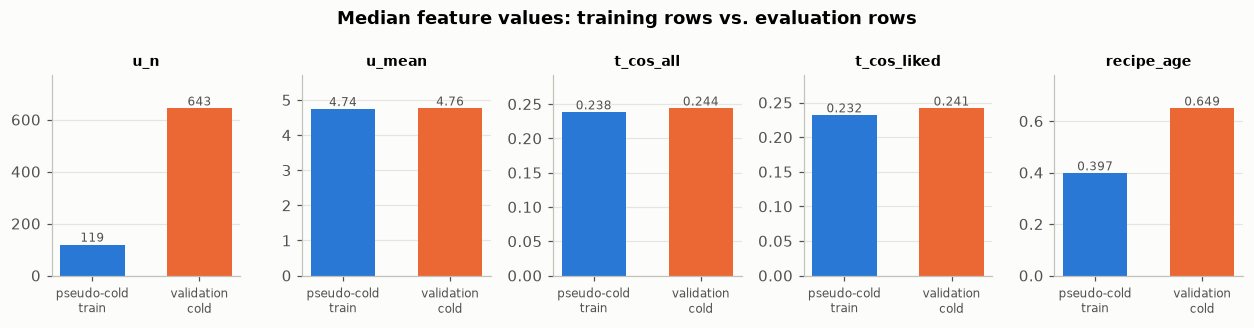

In [6]:
cols = ["u_n", "u_mean", "t_cos_all", "t_cos_liked", "recipe_age"]
P.compare_medians(train_feats[cols].median(), valid_feats.loc[cold, cols].median(),
                  ["pseudo-cold\ntrain", "validation\ncold"], "Median feature values: training rows vs. evaluation rows")

Most features line up. Validation users have much longer histories (they had to be active before 2013), and validation cold rows are for somewhat older recipes (median recipe age 0.65 vs. 0.40 years): first reviews usually come soon after posting. The ablation of the main models checks whether `recipe_age` causes extrapolation problems.

## 3. Evaluation protocol

- **Rows**: validation rows with `cold == 1` (6,410 rows, 859 users); warm rows only as a comparison.
- **Metric**: MSE (the loss we train on, as in the course's rating-prediction task), with RMSE and MAE for readability. Predictions are clipped to [1, 5].
- **Uncertainty**: 95% confidence intervals from 1,000 bootstrap samples that **resample users**; model comparisons use a paired bootstrap of the MSE difference on the same samples.

In [7]:
results, preds = {}, {}
def report(name, pred):
    preds[name] = np.clip(np.asarray(pred, dtype=float), 1, 5)
    results[name] = r = E.evaluate_rating(y_valid[cold], preds[name][cold], users_valid[cold])
    print(f"{name}: validation cold MSE {r['MSE']:.4f} (95% CI {r['CI low']:.4f}-{r['CI high']:.4f}), MAE {r['MAE']:.4f}")

## 4. Baselines

### B0: global mean

Predict the mean of all training ratings for every row.

In [8]:
def fit_b0(history):
    mean = history.rating.mean()
    return lambda df, feats=None: np.full(len(df), mean)

print(f"global mean {train.rating.mean():.3f}; mean of validation cold rows {y_valid[cold].mean():.3f}")
report("B0 global mean", fit_b0(train)(valid))

global mean 4.677; mean of validation cold rows 4.719


B0 global mean: validation cold MSE 0.3532 (95% CI 0.3088-0.4008), MAE 0.4589


### B1: ID-only bias model

The rating-prediction baseline from the course, fit on **all** training ratings:

$$\hat r_{u,i} = \alpha + \beta_u + \beta_i, \qquad \min \sum_{(u,i)} (r_{u,i} - \alpha - \beta_u - \beta_i)^2 + \lambda \Big(\sum_u \beta_u^2 + \sum_i \beta_i^2\Big)$$

solved by alternating closed-form updates. A cold recipe never appears in training, so $\beta_i = 0$ and the prediction is $\alpha + \beta_u$: every cold recipe gets the same prediction for a given user. (Latent factors $\gamma_u \cdot \gamma_i$ would not help either, since an unseen recipe's $\gamma_i$ is never learned; `02_baselines_binary.ipynb` shows this with BPR.)

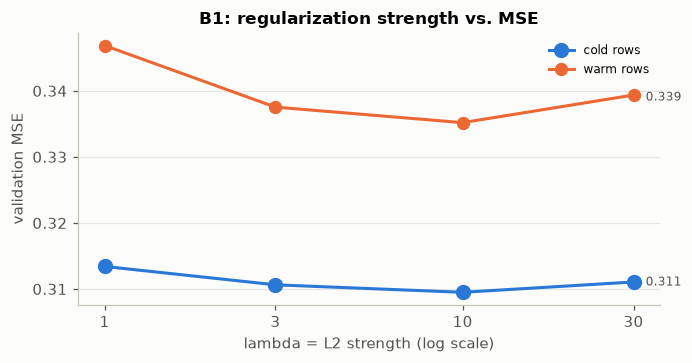

In [9]:
def fit_b1(history, lam, n_iter=30):
    u = history.user_id.astype("category")
    i = history.recipe_id.astype("category")
    uc, ic, r = u.cat.codes.values, i.cat.codes.values, history.rating.values.astype(float)
    bu, bi = np.zeros(len(u.cat.categories)), np.zeros(len(i.cat.categories))
    n_u, n_i = np.bincount(uc, minlength=len(bu)), np.bincount(ic, minlength=len(bi))
    for _ in range(n_iter):
        alpha = (r - bu[uc] - bi[ic]).mean()
        bu = np.bincount(uc, r - alpha - bi[ic], len(bu)) / (lam + n_u)
        bi = np.bincount(ic, r - alpha - bu[uc], len(bi)) / (lam + n_i)
    bu, bi = pd.Series(bu, index=u.cat.categories), pd.Series(bi, index=i.cat.categories)

    def predict(df, feats=None):
        return alpha + bu.reindex(df.user_id).fillna(0).values + bi.reindex(df.recipe_id).fillna(0).values
    predict.alpha, predict.user_bias = alpha, bu
    return predict

b1_grid = []
for lam in [1, 3, 10, 30]:
    predict = fit_b1(train, lam)
    p = predict(valid)
    b1_grid.append({"lambda": lam, "cold MSE": E.evaluate_rating(y_valid[cold], p[cold], users_valid[cold], n_boot=1)["MSE"],
                    "warm MSE": E.evaluate_rating(y_valid[~cold], p[~cold], users_valid[~cold], n_boot=1)["MSE"],
                    "predict": predict, "p": p})
fig, ax = plt.subplots(figsize=(6.5, 3.4))
P.lines(ax, [r["lambda"] for r in b1_grid],
        {"cold rows": [r["cold MSE"] for r in b1_grid], "warm rows": [r["warm MSE"] for r in b1_grid]},
        "lambda = L2 strength (log scale)", "validation MSE", title="B1: regularization strength vs. MSE", xlog=True)
plt.tight_layout(); plt.show()

In [10]:
best_b1 = min(b1_grid, key=lambda r: r["cold MSE"])
b1 = best_b1["predict"]
gap = np.abs(best_b1["p"][cold] - (b1.alpha + b1.user_bias.reindex(valid.user_id[cold]).values)).max()
print(f"lambda = {best_b1['lambda']}: max |prediction - (alpha + beta_u)| on cold rows = {gap:.2e}")
report("B1 ID-only bias model", best_b1["p"])

lambda = 10: max |prediction - (alpha + beta_u)| on cold rows = 0.00e+00
B1 ID-only bias model: validation cold MSE 0.3095 (95% CI 0.2732-0.3506), MAE 0.4036


On cold rows the B1 prediction is exactly $\alpha + \beta_u$: the model only knows how generous each user is, and says nothing about the recipe.

### B2: user-history features

A ridge regression on the time-aware user features, trained on the pseudo-cold rows with squared error. Like B1 it only uses information about the user, but the features are computed as of each review date and the model is fit under cold-start conditions.

In [11]:
USER_COLS = ["u_n", "u_mean", "u_mean_smooth", "u_std", "u_rate"]
def user_matrix(feats):
    return feats[USER_COLS].assign(u_n=np.log1p(feats.u_n))

def fit_b2(rows, feats, w):
    model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    model.fit(user_matrix(feats), rows.rating, ridge__sample_weight=w)
    predict = lambda df, feats: model.predict(user_matrix(feats))
    predict.coef = pd.Series(model[-1].coef_, index=USER_COLS)
    return predict

b2 = fit_b2(train_rows, train_feats, train_w)
print("standardized coefficients:", b2.coef.round(3).to_dict())
report("B2 user features", b2(valid, valid_feats))

standardized coefficients: {'u_n': 0.029999999329447746, 'u_mean': 0.026000000536441803, 'u_mean_smooth': 0.14300000667572021, 'u_std': 0.010999999940395355, 'u_rate': 0.07599999755620956}
B2 user features: validation cold MSE 0.3081 (95% CI 0.2716-0.3494), MAE 0.3847


### B3: TF-IDF cosine (content-only)

Each recipe is represented by the TF-IDF vector of its name, tags, ingredients, description and steps. For a row we compare the recipe with the TF-IDF centroid of the user's earlier recipes: everything the user reviewed (`t_cos_all`) and the recipes the user rated 5 stars (`t_cos_liked`). A ridge regression on these two similarities, fit on the pseudo-cold rows, turns them into a rating. It uses no rating statistics of the user (no mean, no 5-star share), only how close the recipe's text is to what the user has cooked and loved.

In [12]:
def text_matrix(feats):
    liked = feats.t_cos_liked.fillna(feats.t_cos_all)     # user without 5-star history: fall back to all recipes
    return pd.DataFrame({"t_cos_all": feats.t_cos_all.fillna(0), "t_cos_liked": liked.fillna(0)})

def fit_b3(rows, feats, w):
    model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    model.fit(text_matrix(feats), rows.rating, ridge__sample_weight=w)
    predict = lambda df, feats: model.predict(text_matrix(feats))
    predict.coef = pd.Series(model[-1].coef_, index=["t_cos_all", "t_cos_liked"])
    return predict

b3 = fit_b3(train_rows, train_feats, train_w)
print("standardized coefficients:", b3.coef.round(3).to_dict())
report("B3 TF-IDF cosine", b3(valid, valid_feats))

standardized coefficients: {'t_cos_all': -0.33500000834465027, 't_cos_liked': 0.3619999885559082}


B3 TF-IDF cosine: validation cold MSE 0.3439 (95% CI 0.3029-0.3883), MAE 0.4616


The coefficients have opposite signs: the predicted rating is higher when the recipe is close to what the user **loved**, *relative to* what the user usually reviews.

## 5. Validation results

In [13]:
table = pd.DataFrame(results).T

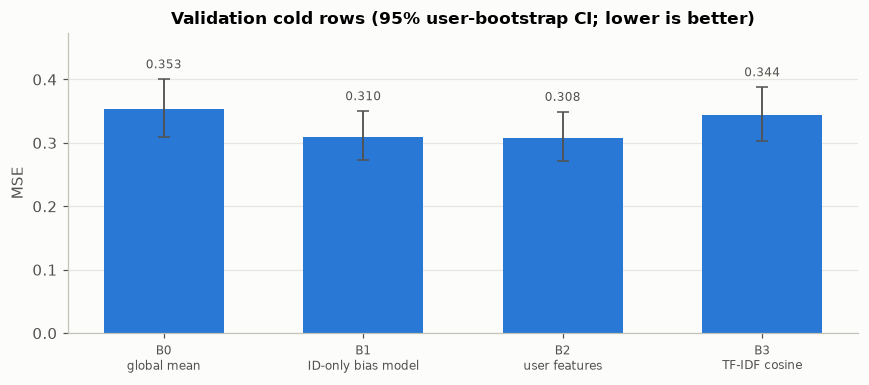

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.6))
P.bars(ax, table.index, table["MSE"], table["CI low"], table["CI high"],
       title="Validation cold rows (95% user-bootstrap CI; lower is better)", ylabel="MSE")
plt.tight_layout(); plt.show()

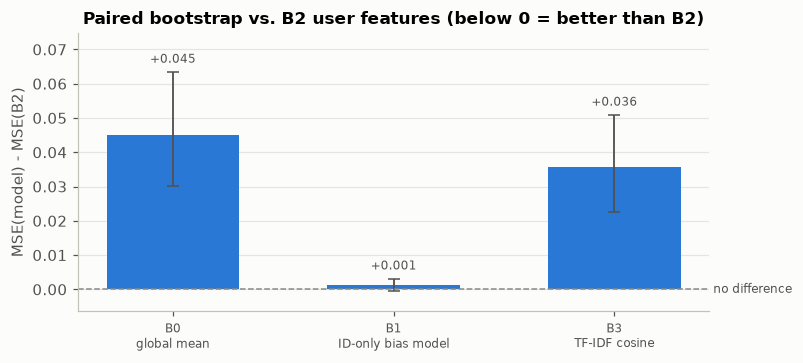

In [15]:
b2_name = "B2 user features"
diff = pd.DataFrame({name: E.compare_rating(y_valid[cold], preds[name][cold], preds[b2_name][cold], users_valid[cold])
                     for name in preds if name != b2_name}).T
P.diff_bars(diff, "MSE diff", f"Paired bootstrap vs. {b2_name} (below 0 = better than B2)", "MSE(model) - MSE(B2)")

The paired comparison reports MSE(model) − MSE(B2): negative means the model is better than B2, and `p(a >= b)` is the share of bootstrap samples in which it is not.

### Where do the errors come from?

Most cold rows are 5-star ratings, which every model predicts reasonably well. The squared error is concentrated in the few low ratings:

In [16]:
by_rating = pd.DataFrame({"rows": pd.Series(y_valid[cold]).value_counts().sort_index()})
for name in [b2_name, "B3 TF-IDF cosine"]:
    err = pd.Series((preds[name][cold] - y_valid[cold]) ** 2).groupby(y_valid[cold])
    by_rating[f"{name.split(' ')[0]} mean prediction"] = pd.Series(preds[name][cold]).groupby(y_valid[cold]).mean()
    by_rating[f"{name.split(' ')[0]} share of squared error"] = err.sum() / err.sum().sum()
by_rating.index.name = "true rating"

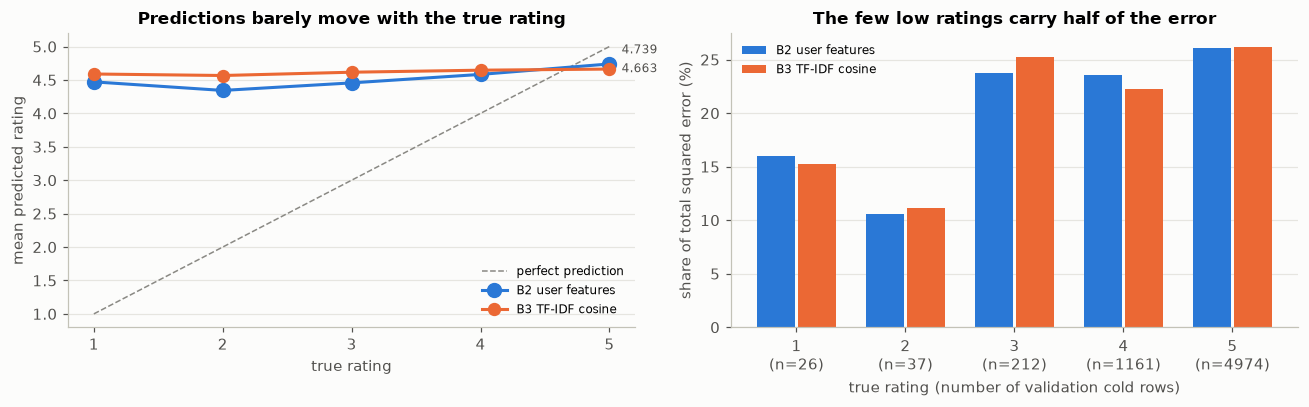

In [17]:
x = by_rating.index.values.astype(int)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(x, x, color=P.GRAY, linestyle="--", linewidth=1, label="perfect prediction")
P.lines(axes[0], x, {b2_name: by_rating["B2 mean prediction"].values, "B3 TF-IDF cosine": by_rating["B3 mean prediction"].values},
        "true rating", "mean predicted rating", title="Predictions barely move with the true rating")

w = 0.38
for k, (name, color) in enumerate([("B2", P.BLUE), ("B3", P.ORANGE)]):
    axes[1].bar(x + (k - 0.5) * w, by_rating[f"{name} share of squared error"] * 100, w - 0.03, color=color,
                label=b2_name if name == "B2" else "B3 TF-IDF cosine")
axes[1].set_xticks(x, [f"{r}\n(n={n})" for r, n in zip(x, by_rating["rows"])])
axes[1].set_xlabel("true rating (number of validation cold rows)")
axes[1].set_ylabel("share of total squared error (%)")
axes[1].set_title("The few low ratings carry half of the error")
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 6. Test split: MSE, AUC, Hit@10 and NDCG@10

Every baseline is refit with the hyperparameters chosen above, now using **train + validation** as history, and evaluated **once** on the test split (2014–2018).

- **MSE** on the 4,099 test cold rows (main metric).
- **AUC**: how well the predicted rating separates 5-star cold reviews from the others, across all users.
- **Hit@10 / NDCG@10**: for each 5-star cold test review (3,263), the recipe is ranked by predicted rating against **99 cold recipes the user never reviewed** (no reviews in train + validation, already submitted at the review date). Tied predictions are broken at random, so a constant prediction gets Hit@10 = 0.10.

MSE and AUC compare rows of *different* users, so knowing which users are generous already helps; Hit@10 and NDCG@10 rank recipes *for one user*, so only information about the recipe can help.

In [18]:
full = pd.concat([train, valid], ignore_index=True)
final_rows, final_feats, final_w, _ = training_set(full)
test_feats = F.build_features(test, full, recipes, content, tfidf=X_text)
test_cold = (test.cold == 1).values
y_test = test.rating.values.astype(float)
users_test = test.user_id.values

reviewed = pd.concat([train, valid, test]).groupby("user_id").recipe_id.agg(set).to_dict()
cold_pool = recipes.index[~recipes.index.isin(full.recipe_id)]
positives = test[test_cold & (test.rating == 5)]
cands = E.sample_candidates(positives, cold_pool, reviewed, recipes.submitted)
cand_feats = F.build_features(cands, full, recipes, content, tfidf=X_text)
print(f"final training rows: {len(final_rows):,}; test cold rows: {test_cold.sum()}; "
      f"ranking lists: {len(positives)} x {cands.groupby('group').size().iloc[0]} candidates (pool of {len(cold_pool):,} cold recipes)")

final training rows: 156,779; test cold rows: 4099; ranking lists: 3263 x 100 candidates (pool of 6,714 cold recipes)


In [19]:
final = {
    "B0 global mean": fit_b0(full),
    "B1 ID-only bias model": fit_b1(full, best_b1["lambda"]),
    "B2 user features": fit_b2(final_rows, final_feats, final_w),
    "B3 TF-IDF cosine": fit_b3(final_rows, final_feats, final_w),
}

test_mse, test_rank = {}, {}
for name, predict in final.items():
    p = np.clip(predict(test, test_feats), 1, 5)
    test_mse[name] = E.evaluate_rating(y_test[test_cold], p[test_cold], users_test[test_cold])
    auc = E.evaluate((y_test[test_cold] == 5).astype(int), p[test_cold], users_test[test_cold], is_prob=False)
    rank = E.ranking_metrics(cands, predict(cands, cand_feats))
    hit = E.mean_ci(rank["Hit@10"], positives.user_id.values)
    ndcg = E.mean_ci(rank["NDCG@10"], positives.user_id.values)
    test_rank[name] = {"AUC": auc["AUC"], "AUC low": auc["CI low"], "AUC high": auc["CI high"],
                       "Hit@10": hit[0], "Hit@10 low": hit[1], "Hit@10 high": hit[2],
                       "NDCG@10": ndcg[0], "NDCG@10 low": ndcg[1], "NDCG@10 high": ndcg[2]}
test_mse = pd.DataFrame(test_mse).T
test_rank = pd.DataFrame(test_rank).T

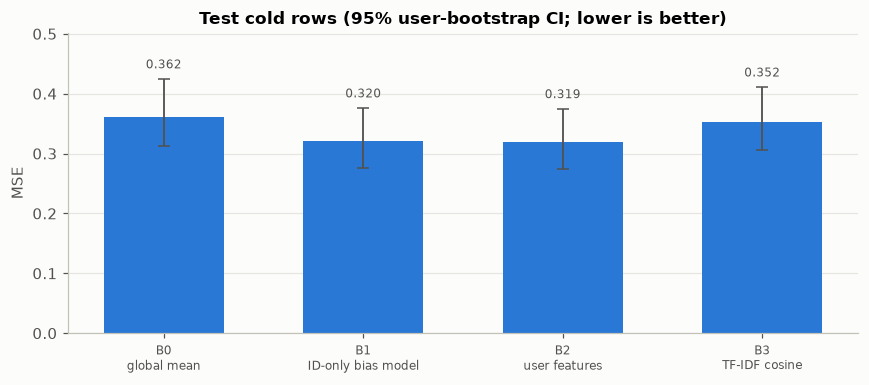

In [20]:
fig, ax = plt.subplots(figsize=(8, 3.6))
P.bars(ax, test_mse.index, test_mse["MSE"], test_mse["CI low"], test_mse["CI high"],
       title="Test cold rows (95% user-bootstrap CI; lower is better)", ylabel="MSE")
plt.tight_layout(); plt.show()

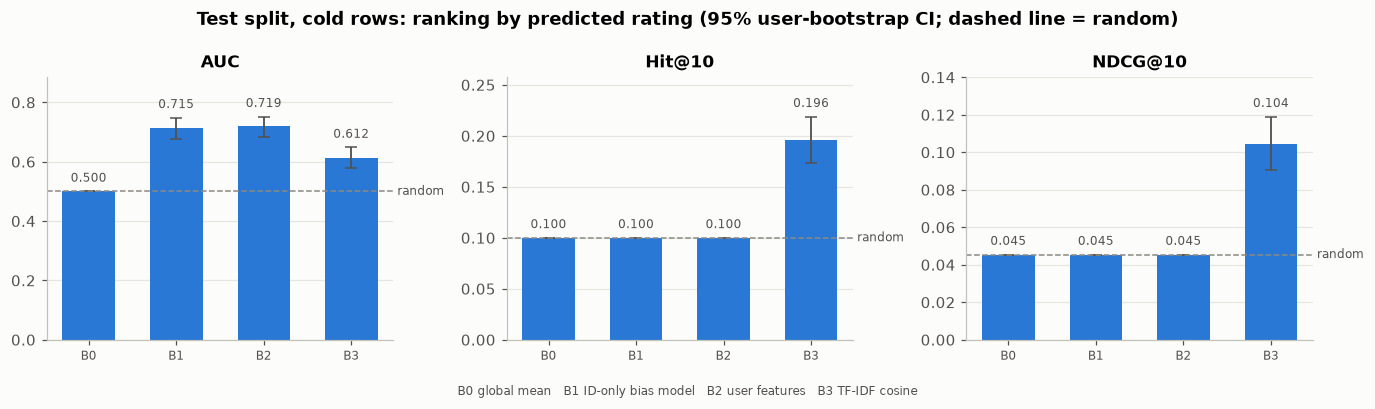

In [21]:
random_ndcg = E.ranking_metrics(cands, np.zeros(len(cands)))["NDCG@10"].mean()
P.metric_bars(test_rank, ["AUC", "Hit@10", "NDCG@10"], refs={"AUC": 0.5, "Hit@10": 0.1, "NDCG@10": random_ndcg},
              suptitle="Test split, cold rows: ranking by predicted rating (95% user-bootstrap CI; dashed line = random)")

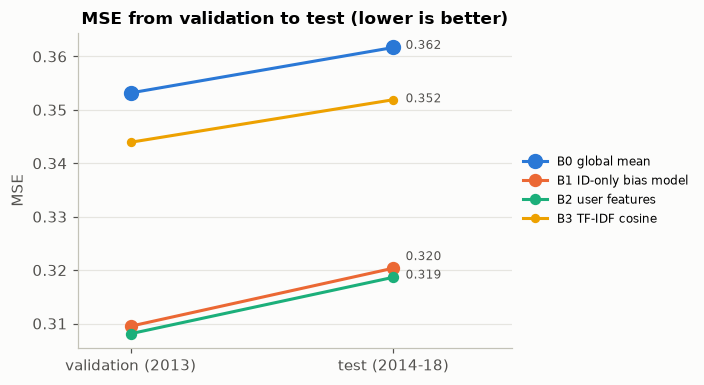

In [22]:
P.val_test_lines(table["MSE"], test_mse["MSE"], "MSE", lower_is_better=True)

### Takeaways


- **User information drives MSE.** B1 and B2 lower the MSE well below the global mean and are statistically indistinguishable (validation paired difference +0.001, CI includes 0). On cold rows B1 is exactly $\alpha + \beta_u$: it knows how generous a user is, nothing about the recipe.
- **Recipe content drives ranking.** Within one user's candidate list, B0–B2 give every recipe the same prediction, so their Hit@10 and NDCG@10 equal random guessing. B3, which only uses text similarity to the user's past recipes, roughly doubles them (test Hit@10 0.196, NDCG@10 0.104), but its MSE is significantly worse than B2 (validation paired difference +0.036, CI +0.023 to +0.051) because it ignores the user's rating level.
- **The errors come from the rare low ratings.** The 275 validation rows rated 1–3 (4% of cold rows) account for about half of the squared error, and every model still predicts them at 4.3–4.6. The test rows are slightly harder for every model (higher MSE than validation), but the ranking of the models is the same.
- **The bar for the main models (M1–M3)** is to match or beat B2 on MSE *and* B3 on Hit@10 / NDCG@10 by combining user history, recipe content, user × recipe match and author features.